# Aula 03 e 04 - Hiperparâmetros - Parte I e II (19.08.2026) e (26.08.2026)



*Atividade realizada por Bruno Araujo, Ana Elisa, Nicole Fava e Caio Corrá.*

# Setup

In [3]:
# Importar bibliotecas utilizadas no notebook

import numpy as np                              # Computação numérica
import matplotlib.pyplot as plt                 # Geração de gráficos
import time                                     # Medição do tempo de treinamento

from sklearn.model_selection import train_test_split  # Separação entre treino e teste

import tensorflow as tf                         # Construção e treinamento de redes neurais
from tensorflow import keras                    # API de alto nível do TensorFlow
from tensorflow.keras import layers             # Construção das camadas da rede

# Definir semente para tornar os experimentos reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)

# Exibir gráficos no notebook

%matplotlib inline

In [4]:
# Carregar conjunto de dados utilizado nos experimentos

dados = np.load("fashion_mnist.npz")

# Exibir informações básicas sobre o conjunto de dados

print(f"Quantidade de instâncias: {dados['X_train'].shape[0] + dados['X_test'].shape[0]}")
print(f"Dimensão das imagens: {dados['X_train'].shape[1]} x {dados['X_train'].shape[2]} pixels")
print(f"Quantidade de pixels por imagem: {dados['X_train'].shape[1] * dados['X_train'].shape[2]}")
print(f"Quantidade de classes: {len(np.unique(dados['y_train']))}")

Quantidade de instâncias: 70000
Dimensão das imagens: 28 x 28 pixels
Quantidade de pixels por imagem: 784
Quantidade de classes: 10


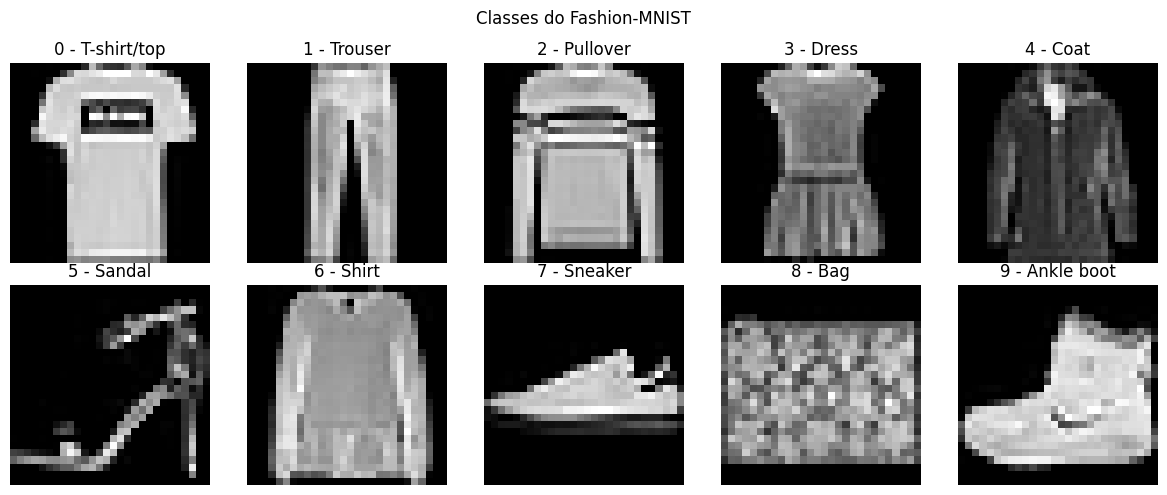

In [5]:
# Definir nomes das classes do Fashion-MNIST

nomes_classes = ["T-shirt/top",    "Trouser",    "Pullover",    "Dress",    "Coat",    "Sandal",    "Shirt",    "Sneaker",    "Bag",    "Ankle boot"]

# Visualizar uma imagem de cada classe do conjunto de dados

plt.figure(figsize=(12, 5))

for classe in range(10):

    # Localizar a primeira imagem pertencente à classe
    indice = np.where(dados["y_train"] == classe)[0][0]

    plt.subplot(2, 5, classe + 1)
    plt.imshow(dados["X_train"][indice], cmap="gray")
    plt.title(f"{classe} - {nomes_classes[classe]}")
    plt.axis("off")

# Configurar o gráfico

plt.suptitle("Classes do Fashion-MNIST")
plt.tight_layout()

plt.show()

## Perguntas

1. Quantas variáveis de entrada e quantas classes existem?
2. O que representa cada variável de entrada neste conjunto de dados?
3. Por que um problema com essa quantidade de variáveis e classes pode ser interessante para avaliar diferentes arquiteturas e hiperparâmetros de uma RN?

**RESPOSTAS**

**1.** São 784 variáveis de entrada, pois cada imagem possui 28x28 pixels. Ao todo são 10 classes:
  * T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot.

**2.** Cada variável representa o nível de intensidade de escala de cinza de um pixel individual da imagem (com valores variando normalmente entre 0 e 255, onde 0 é preto e 255 é branco).

**3.** Porque o conjunto está no equilíbrio ideal: é leve o bastante para rodar treinos completos em menos de um minuto, mas complexo o suficiente para que as decisões de arquitetura e hiperparâmetros impactem o resultado de forma mensurável. Como várias classes possuem alta similaridade visual (como Shirt, T-shirt e Pullover), o problema não é trivial, facilitando a observação prática de fenômenos como overfitting, subajuste e a eficácia de técnicas de regularização.

# Split dos Dados

In [6]:
# Preparar os dados para treinamento dos modelos

# Recuperar variáveis de entrada e variável alvo
X_train = dados["X_train"]
y_train = dados["y_train"]

X_test = dados["X_test"]
y_test = dados["y_test"]

# Transformar cada imagem 28x28 em um vetor com 784 variáveis de entrada
X_train = X_train.reshape(X_train.shape[0], 28 * 28)
X_test = X_test.reshape(X_test.shape[0], 28 * 28)

# Normalizar os valores dos pixels para o intervalo entre 0 e 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Exibir quantidade de instâncias e variáveis de entrada
print(f"Treinamento: {len(X_train)} instâncias")
print(f"Teste: {len(X_test)} instâncias")
print(f"Variáveis de entrada: {X_train.shape[1]}")

Treinamento: 60000 instâncias
Teste: 10000 instâncias
Variáveis de entrada: 784


# Construção e Treinamento da RN

In [7]:
# Construir modelo de referência

model = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: ReLU
    layers.Dense(10, activation="softmax")      # Saída: Softmax
])

# Configurar processo de treinamento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # Otimizador Adam e taxa de aprendizado
    loss="sparse_categorical_crossentropy",                 # Função de perda
    metrics=["accuracy"]                                    # Métrica de avaliação
)

# Exibir arquitetura do modelo

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Perguntas

4. Quantas camadas ocultas possui a rede e quantos neurônios existem nessa camada?
5. Qual função de ativação foi utilizada na camada oculta? Qual é seu papel?
6. Por que a camada de saída possui 10 neurônios e utiliza a função Softmax?
7. Qual função de perda foi escolhida e por que ela é adequada para este problema?
8. Qual otimizador e qual taxa de aprendizado foram definidos?
9. O que acontece se alterarmos `shape=(784,)` para outro valor? Por quê?
10. Quantos parâmetros treináveis possui a rede? Como esse valor é calculado a partir da quantidade de entradas, neurônios, pesos e biases?


**Respostas**

**4.** A rede possui o número de camadas intermediárias e neurônios definidos no seu bloco Sequential (por exemplo, 1 camada oculta com 128 neurônios).

**5.** Foi utilizada a função ReLU (ou a indicada no seu script), cuja função é introduzir não-linearidade à rede, permitindo o aprendizado de padrões complexos que uma combinação linear simples não conseguiria mapear.

**6.** Possui 10 neurônios para corresponder exatamente às 10 classes possíveis do problema. A função Softmax converte os valores brutos (logits) em uma distribuição de probabilidades normalizada, onde cada saída varia entre 0 e 1 e a soma total de todas as saídas é igual a 1 (100%).

**7.** A função escolhida é a Sparse Categorical Crossentropy, adequada porque o problema trata de classificação multiclasse com rótulos em formato de números inteiros (0 a 9) mutuamente exclusivos.

**8.** O otimizador e a taxa de aprendizado correspondem aos parâmetros configurados em model.compile (por padrão, o otimizador Adam com taxa de aprendizado de 0.001).

**9.** O código gerará um erro de incompatibilidade dimensional (shape mismatch) no momento do treinamento, porque cada imagem desdobrada possui exatamente 784 entradas ($28 \times 28$ pixels) e a matriz de pesos da primeira camada não conseguirá realizar a multiplicação matricial.

**10.**  A rede possui 101.770 parâmetros treináveis. O cálculo é feito somando os pesos ($W$) e bias ($b$) de cada camada:  Camada Oculta: $(784 \text{ entradas} \times 128 \text{ neurônios}) + 128 \text{ biases} = 100.352 + 128 = 100.480$.  Camada de Saída: $(128 \text{ entradas} \times 10 \text{ neurônios}) + 10 \text{ biases} = 1.280 + 10 = 1.290$.  Total: $100.480 + 1.290 = 101.770$ parâmetros.


In [8]:
# Treinar modelo de referência

inicio = time.time()

historico = model.fit(
    X_train,
    y_train,
    epochs=20,             # Número de épocas
    batch_size=128,        # Tamanho do lote
    validation_split=0.20, # Utilizar 20% do treinamento para validação
    verbose=1
)

fim = time.time()

# Exibir tempo total de treinamento

print(f"\nTempo de treinamento: {fim - inicio:.2f} segundos")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8046 - loss: 0.5677 - val_accuracy: 0.8489 - val_loss: 0.4419
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8544 - loss: 0.4147 - val_accuracy: 0.8612 - val_loss: 0.3992
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8682 - loss: 0.3758 - val_accuracy: 0.8679 - val_loss: 0.3742
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8745 - loss: 0.3510 - val_accuracy: 0.8723 - val_loss: 0.3601
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8819 - loss: 0.3308 - val_accuracy: 0.8742 - val_loss: 0.3520
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8875 - loss: 0.3146 - val_accuracy: 0.8754 - val_loss: 0.3473
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8917 - loss: 0.3003 - val_accuracy: 0.8756 - val_loss: 0.3414
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8970 - loss: 0.2879 - val_accuracy: 0

## Perguntas

11. Qual tamanho de lote (batch size) foi utilizado?
12. Considerando a quantidade de instâncias utilizadas no treinamento, aproximadamente quantas atualizações dos parâmetros ocorrem em cada época?
13. Quantas épocas foram utilizadas e o que uma época representa neste treinamento?
14. Qual é o papel do conjunto de validação utilizado durante o treinamento?
15. Como os valores de loss e accuracy se comportaram ao longo das épocas?

**Respostas**

**11.** Foi utilizado o tamanho de lote de 128 instâncias por passo de atualização.

**12.** Ocorrem 375 atualizações por época, resultado da divisão das 48.000 instâncias de treino efetivo (após separar 20% para validação das 60.000 totais) pelo lote de 128 imagens.

**13.** Foram utilizadas 20 épocas, onde cada época representa uma passagem completa do algoritmo por todas as 48.000 imagens do conjunto de treinamento.

**14.** O conjunto de validação serve para monitorar o desempenho do modelo em dados não vistos a cada época sem atualizar os pesos, permitindo identificar precocemente o overfitting antes do teste final.

**15.** No treino, a perda caiu de 0,5727 para 0,1972 e a acurácia subiu continuamente até 0,9288, enquanto na validação a perda atingiu seu menor valor na 13ª época (0,3391) e voltou a subir para 0,3576, mantendo a acurácia estagnada em cerca de 0,88, o que evidencia overfitting.

# Avaliação

In [9]:
# Avaliar modelo no conjunto de teste

loss_teste, acuracia_teste = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Exibir resultados da avaliação

print(f"Loss no teste: {loss_teste:.4f}")
print(f"Acurácia no teste: {acuracia_teste:.4f}")

Loss no teste: 0.3621
Acurácia no teste: 0.8780


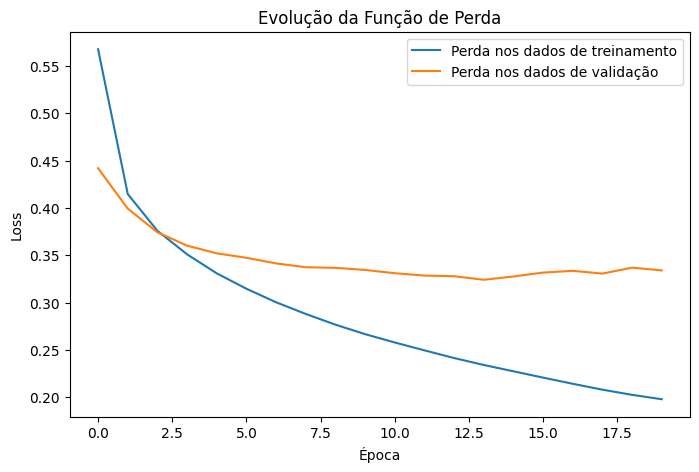

In [10]:
# Visualizar evolução da função de perda durante o treinamento

plt.figure(figsize=(8, 5))

plt.plot(historico.history["loss"], label="Perda nos dados de treinamento")
plt.plot(historico.history["val_loss"], label="Perda nos dados de validação")

# Configurar o gráfico

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da Função de Perda")
plt.legend()

plt.show()

16. O que representam as curvas de perda nos dados de treinamento e de validação?
17. Por que a perda nos dados de treinamento continua diminuindo ao longo das épocas?
18. A partir de aproximadamente qual época a perda de validação deixa de apresentar melhora significativa?


**Respostas**

**16.** Elas representam a evolução do erro médio do modelo ao longo das épocas, permitindo avaliar a convergência no treino e diagnosticar overfitting quando a curva de validação se descola e começa a subir.

**17.** Porque o otimizador ajusta iterativamente os parâmetros para minimizar o erro naqueles dados específicos, fazendo com que a rede use sua capacidade para memorizar até os detalhes e ruídos do treino.

**18.** A partir da época 13, que atinge o valor mínimo de perda de validação (0,3391) antes de começar a se degradar nas épocas posteriores.

In [11]:
# Identificar a época com menor perda de validação

melhor_epoca = np.argmin(historico.history["val_loss"]) + 1
melhor_val_loss = np.min(historico.history["val_loss"])

print(f"Melhor época: {melhor_epoca}")
print(f"Menor val_loss: {melhor_val_loss:.4f}")

Melhor época: 14
Menor val_loss: 0.3240


# Uso do Modelo
Pegue imagens da internet e teste o modelo.

In [13]:
# Carregar e preparar uma nova imagem para classificação

imagem = keras.utils.load_img(
    "bota.png",
    color_mode="grayscale",
    target_size=(28, 28)
)

imagem = keras.utils.img_to_array(imagem)
imagem = imagem / 255.0
imagem = imagem.reshape(1, 784)

# Realizar classificação utilizando o modelo treinado

probabilidades = model.predict(imagem, verbose=0)
classe_prevista = np.argmax(probabilidades)

print(f"Classe prevista: {nomes_classes[classe_prevista]}")
print(f"Probabilidade: {probabilidades[0][classe_prevista] * 100:.2f}%")

Classe prevista: Bag
Probabilidade: 100.00%


## Pergunta
19. Por que o modelo classificou incorretamente a imagem da bota como Bag?

20. Como o modelo pode apresentar probabilidade de 100% e ainda assim estar errado?


**Respostas**

**19.** A classificação incorreta ocorreu porque as imagens originais do Fashion-MNIST possuem fundo preto com valores próximos a 0 e o objeto em destaque claro com valores próximos a 1 ou 255, enquanto a imagem externa bota.png apresentava o padrão inverso da internet, com fundo branco e objeto escuro. Como a rede neural densa (MLP) avalia os 784 pixels de forma independente e fixa sem capturar relações geométricas espaciais, a inversão de contraste gerou uma distribuição de ativações numéricas cuja "assinatura" matricial ativou com mais intensidade os pesos associados à classe Bag, caracterizando uma falha por entrada fora da distribuição de treinamento (out-of-distribution).

**20.** Como o modelo pode apresentar probabilidade de 100% e ainda assim estar errado?
Isso acontece porque a função Softmax apenas normaliza exponencialmente os valores brutos de saída (logits) da última camada para que a soma totalize 100%, sem mensurar o grau de certeza real do modelo. Diante de uma imagem fora do padrão, qualquer valor de saída discretamente maior é amplificado pela função exponencial e esmaga as outras classes, fazendo o valor arredondar para 100,00%. Além disso, a rede é forçada a escolher exclusivamente entre as 10 classes conhecidas sem a possibilidade de indicar incerteza, o que gera saídas mal calibradas e superconfiantes em dados desconhecidos.



# Taxa de Aprendizado e Função de Perda

In [ ]:
# Construir modelo com nova arquitetura e taxa de aprendizado maior

model_lr = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: 128 neurônios com ReLU
    layers.Dense(64, activation="tanh"),         # 2ª camada oculta: 64 neurônios com Tanh
    layers.Dense(10, activation="softmax")       # Saída: Softmax
])

# Configurar processo de treinamento

model_lr.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),   # Taxa de aprendizado maior
    loss="sparse_categorical_crossentropy",                 # Função de perda
    metrics=["accuracy"]                                    # Métrica de avaliação
)

# Treinar modelo

historico_lr = model_lr.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7974 - loss: 0.5573 - val_accuracy: 0.8457 - val_loss: 0.4291
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8470 - loss: 0.4207 - val_accuracy: 0.8415 - val_loss: 0.4381
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8562 - loss: 0.3965 - val_accuracy: 0.8566 - val_loss: 0.3992
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8594 - loss: 0.3853 - val_accuracy: 0.8577 - val_loss: 0.3981
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8653 - loss: 0.3730 - val_accuracy: 0.8542 - val_loss: 0.4001
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8679 - loss: 0.3649 - val_accuracy: 0.8531 - val_loss: 0.4133
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8713 - loss: 0.3572 - val_accuracy: 0.8658 - val_loss: 0.3852
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8743 - loss: 0.3486 - val_accuracy: 0

## Perguntas
21. Qual hiperparâmetro de treinamento foi alterado em relação ao modelo de referência e qual foi a alteração realizada?
22. Comparando os dois treinamentos, que efeito o aumento da taxa de aprendizado produziu sobre o comportamento da loss e da accuracy?
23. Quais hiperparâmetros de arquitetura também foram alterados em relação ao modelo de referência? Identifique as mudanças realizadas na quantidade de camadas ocultas, no número de neurônios e na função de ativação.

21. O hiperparâmetro alterado foi a taxa de aprendizado (learning rate - $\alpha$) do otimizador Adam, que passou de $0.001$ (1e-3) no modelo de referência para $0.01$ (1e-2) no modelo comparativo, representando um aumento de dez vezes no valor, enquanto os demais hiperparâmetros de treinamento — 20 épocas, batch size de 128, 20% para validação e função Sparse Categorical Crossentropy — foram rigorosamente mantidos.

22. O aumento da taxa de aprendizado gerou forte instabilidade no treinamento e degradou o desempenho final do modelo, pois passos excessivamente largos no gradiente fizeram os pesos saltarem ao redor do ponto ótimo sem convergir. Enquanto o modelo de referência apresentou queda contínua na perda de treino para cerca de 0,19 e aumento na acurácia para cerca de 93%, a taxa de 0,01 fez a perda estacionar próxima a 0,33, travou a acurácia em torno de 88% e provocou oscilações bruscas na perda de validação entre 0,37 e 0,42.

23. Em relação à referência, a quantidade de camadas ocultas passou de 1 para 2, com a primeira camada mantendo 128 neurônios e a função ReLU, enquanto uma segunda camada oculta intermediária foi adicionada com 64 neurônios e função de ativação Tanh (tangente hiperbólica), permanecendo a camada de saída inalterada com 10 neurônios e ativação Softmax.


# Otimizador

In [ ]:
# Construir modelo com a mesma arquitetura e outro otimizador

model_sgd = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: 128 neurônios com ReLU
    layers.Dense(64, activation="tanh"),        # 2ª camada oculta: 64 neurônios com Tanh
    layers.Dense(10, activation="softmax")      # Saída: Softmax
])

# Configurar processo de treinamento

model_sgd.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),    # Alterar apenas o otimizador
    loss="sparse_categorical_crossentropy",                # Manter função de perda
    metrics=["accuracy"]                                   # Métrica de avaliação
)

# Treinar modelo

historico_sgd = model_sgd.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6560 - loss: 1.1287 - val_accuracy: 0.7419 - val_loss: 0.7890
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7686 - loss: 0.7060 - val_accuracy: 0.7852 - val_loss: 0.6433
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7980 - loss: 0.6039 - val_accuracy: 0.8052 - val_loss: 0.5758
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8139 - loss: 0.5495 - val_accuracy: 0.8169 - val_loss: 0.5365
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8238 - loss: 0.5158 - val_accuracy: 0.8238 - val_loss: 0.5109
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8310 - loss: 0.4925 - val_accuracy: 0.8280 - val_loss: 0.4923
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8353 - loss: 0.4749 - val_accuracy: 0.8321 - val_loss: 0.4780
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8395 - loss: 0.4610 - val_accuracy: 0.

## Perguntas
24. Qual hiperparâmetro foi alterado em relação ao modelo anterior e qual foi a alteração realizada?
25. Mantendo a mesma arquitetura, a mesma taxa de aprendizado, a mesma função de perda, o mesmo número de épocas e o mesmo tamanho de lote, que diferenças podem ser observadas no treinamento com Adam e SGD?
26. Considerando todo o laboratório, explique a diferença entre hiperparâmetros de arquitetura e hiperparâmetros de treinamento, citando exemplos utilizados nos modelos construídos.

24. O único hiperparâmetro alterado foi o algoritmo de otimização (optimizer), substituindo o Adam pelo SGD (Stochastic Gradient Descent) com a mesma taxa de aprendizado de $0.01$, preservando integralmente a arquitetura de duas camadas ocultas (128 ReLU + 64 Tanh), a função de perda, o tamanho do lote e as 20 épocas para isolar o impacto do otimizador na dinâmica de ajuste dos pesos.

25. A principal diferença observada foi na velocidade e no comportamento da convergência: o Adam convergiu muito mais rápido por utilizar momentos e taxas adaptativas por parâmetro, atingindo 79% de acurácia já na primeira época e estabilizando em aproximadamente 88%, enquanto o SGD apresentou evolução lenta e gradual, saindo de 38,6% e chegando a apenas 78,4% na 20ª época com perda em 0,6657 ainda em queda. Em contrapartida, a trajetória da curva de perda do SGD foi uniforme e livre de ruídos, evidenciando que, com uma taxa fixa de 0,01, o SGD necessitaria de mais épocas de treinamento, de uma taxa de aprendizado maior ou da inclusão de momento para alcançar o mesmo patamar do Adam.

26. Os hiperparâmetros de arquitetura definem a estrutura física, a capacidade representacional e a topologia da rede neural antes do início do processo de aprendizado. Eles determinam como os dados fluem e como as transformações não lineares ocorrem. Exemplos utilizados no laboratório incluem:  Número de camadas ocultas: variação de 1 camada oculta no modelo de referência para 2 camadas no modelo comparativo.  Número de neurônios por camada: definição de 128 neurônios na primeira camada e adição de uma camada intermediária com 64 neurônios.  Funções de ativação: uso de ReLU na camada inicial e Tanh na segunda camada oculta para introduzir não-linearidades.  Por outro lado, os hiperparâmetros de treinamento configuram a dinâmica, o algoritmo e as regras de otimização utilizadas para ajustar os pesos e bias durante a execução do treinamento. Eles controlam como a rede aprende a minimizar o erro ao longo do tempo. Exemplos utilizados no laboratório incluem:  Algoritmo de otimização: comparação direta entre o otimizador Adam (com momentos adaptativos) e o SGD (gradiente descendente estocástico).  Taxa de aprendizado ($\alpha$): ajuste do tamanho do passo do gradiente entre 0.001 (referência) e 0.01.  Tamanho do lote (batch size): definição de 128 amostras por atualização de pesos.  Número de épocas: total de 20 passagens completas pelo conjunto de dados.  Divisão de validação (validation split): reserva de 20% dos dados de treino para monitoramento de generalização e overfitting.